# AlphaEvolve + **Qwen3-VL-2B-Instruct** on **EvoChart-QA** — Google Colab

Runs **AlphaEvolve** (`evolve_evochartqa.py`) with `evaluate_evochartqa.py` on **gsarch/EvoChart-QA**.

**Optional uploads:** After the project folder exists, you may upload your own `evolve_evochartqa.py` and/or `evolved_evochartqa.py` into `evolving-vlm-inference-main/` (Colab sidebar) to replace the repo copies before running evolution or the post-evolution benchmark.

**Colab:** **Runtime → GPU**. **Secrets:** `HF_TOKEN`, `GEMINI_API_KEY`.

**Before/after demo:** Same `SAMPLE` chart — EXAMPLE cells use `seed_instruct.py` then `evolved_evochartqa.py`; the visual demo scans for a contrastive hit (seed wrong → evolved right).

**Project path:** `/content/evolving-vlm-325/evolving-vlm-inference-main` (upload or `GIT_REPO_URL`).


In [ ]:
import os
from pathlib import Path

PROJECT_ROOT = Path(os.environ.get("COLAB_PROJECT_ROOT", "/content/evolving-vlm-325/evolving-vlm-inference-main"))
GIT_REPO_URL = os.environ.get("GIT_REPO_URL", "")

NUM_GENERATIONS = int(os.environ.get("NUM_GENERATIONS", "3"))
POPULATION_SIZE = int(os.environ.get("POPULATION_SIZE", "6"))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("NUM_GENERATIONS:", NUM_GENERATIONS, "POPULATION_SIZE:", POPULATION_SIZE)



PROJECT_ROOT: /content/evolving-vlm-325/evolving-vlm-inference-main
NUM_GENERATIONS: 3 POPULATION_SIZE: 6


In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("/content/projectFiles.zip")  # change if your file name differs
out_dir = Path("/content")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(out_dir)

# If the zip already contains a top-level folder "evolving-vlm-inference-main", you're done.
# If it extracted into a wrong name, rename so this path exists:
assert (out_dir / "evolving-vlm-325/evolving-vlm-inference-main").is_dir(), list(out_dir.iterdir())



In [ ]:
%%capture
!pip install -q "transformers>=4.37.0" qwen-vl-utils torch torchvision pillow accelerate google-generativeai bitsandbytes datasets huggingface_hub



In [ ]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU. In Colab: Runtime → Change runtime type → GPU (e.g. T4), then re-run."
    )
print("GPU:", torch.cuda.get_device_name(0))



GPU: NVIDIA A100-SXM4-80GB


In [ ]:
import os, shutil, subprocess
from pathlib import Path

if GIT_REPO_URL:
    if PROJECT_ROOT.exists():
        shutil.rmtree(PROJECT_ROOT)
    subprocess.run(["git", "clone", "--depth", "1", GIT_REPO_URL, str(PROJECT_ROOT)], check=True)
elif not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"{PROJECT_ROOT} not found. Upload repo to /content/evolving-vlm-325/evolving-vlm-inference-main or set GIT_REPO_URL."
    )

os.chdir(PROJECT_ROOT)
print("cwd:", os.getcwd())



cwd: /content/evolving-vlm-325/evolving-vlm-inference-main


In [ ]:
# Optional: upload evolve_evochartqa.py / evolved_evochartqa.py into PROJECT_ROOT.
print("Optional: upload evolve_evochartqa.py or evolved_evochartqa.py into", PROJECT_ROOT)



Optional: upload evolve_evochartqa.py or evolved_evochartqa.py into /content/evolving-vlm-325/evolving-vlm-inference-main


In [ ]:
# import os
# from google.colab import userdata

# try:
#     os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
# except Exception:
#     from huggingface_hub import login
#     login()

# try:
#     os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
# except Exception:
#     pass

# if not os.environ.get("GEMINI_API_KEY"):
#     from getpass import getpass
#     os.environ["GEMINI_API_KEY"] = getpass("Enter GEMINI_API_KEY: ")

# assert os.environ.get("GEMINI_API_KEY"), "GEMINI_API_KEY is required."
import os
from google.colab import userdata
from huggingface_hub import login

# ---------- HF TOKEN ----------
try:
    hf_token = userdata.get("HF_TOKEN")
    os.environ["HF_TOKEN"] = hf_token
    login(token=hf_token)
    print("HF login successful")
except Exception:
    print("HF_TOKEN not found in Colab secrets")

# ---------- GEMINI API ----------
try:
    os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
except Exception:
    pass

if not os.environ.get("GEMINI_API_KEY"):
    from getpass import getpass
    os.environ["GEMINI_API_KEY"] = getpass("Enter GEMINI_API_KEY: ")

assert os.environ.get("GEMINI_API_KEY"), "GEMINI_API_KEY is required."





Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HF login successful


In [ ]:
import os
import sys
import importlib.util
from pathlib import Path

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))


def load_module(name: str, path: Path):
    spec = importlib.util.spec_from_file_location(name, path)
    m = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(m)
    return m


from datasets import load_dataset

_sample_dir = Path("/tmp/evochartqa_colab_sample")
_sample_dir.mkdir(parents=True, exist_ok=True)
_ds = load_dataset("gsarch/EvoChart-QA", split="train")
_row = _ds[0]
_img = _row["image"]
_p = _sample_dir / "sample0.png"
if hasattr(_img, "convert"):
    _img.convert("RGB").save(_p)
_gold = str(_row.get("answer") or "").strip()
SAMPLE = {"image_path": str(_p), "question": _row["question"], "qid": None, "gold": _gold}
print("Sample:", SAMPLE["question"][:120], "Gold:", SAMPLE["gold"])



README.md:   0%|          | 0.00/356 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/157M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1250 [00:00<?, ? examples/s]

Sample: What is the value of December? Gold: 32


In [ ]:
initial = load_module("alphaevolve_seed_colab", PROJECT_ROOT / "seed_instruct.py")
before_pred = initial.vlm_inference(SAMPLE["image_path"], SAMPLE["question"], SAMPLE["qid"])
print("=== EXAMPLE — generation 0 (EvoChart-QA) ===")
print("Prediction:", before_pred)
print("Gold      :", SAMPLE["gold"])


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/4.26G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

...

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


=== EXAMPLE — generation 0 (EvoChart-QA) ===
Prediction: Based on the provided chart, we can determine the value for December by following these steps:

1.  **Identify the time period:** The x-axis (horizontal axis) represents the timeline from October 2019 to June 2020.
2.  **Locate the month:** Find the label "DEC" on the x-axis. This corresponds to December.
3.  **Read the corresponding value:** The y-axis (vertical axis) represents the sales in thousands of USD. The black line, which represents the actual sales, shows the value for December.

The chart indicates that the actual sales in December 
Gold      : 32


In [ ]:
from evaluate_evochartqa import evaluate

print("=== BENCHMARK — generation 0 ===")
bench_before = evaluate(initial, return_details=False)
for k in ("desc_accuracy", "num_desc_evaluated", "num_errors", "total_time", "avg_time_per_query"):
    print(f"  {k}: {bench_before[k]}")


=== BENCHMARK — generation 0 ===


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  desc_accuracy: 0.010416666666666666
  num_desc_evaluated: 192
  num_errors: 0
  total_time: 981.108448266983
  avg_time_per_query: 5.10993983472387


In [ ]:
import gc, sys, torch
_mname = "alphaevolve_seed_colab"
if _mname in sys.modules:
    mod = sys.modules.pop(_mname)
    for attr in ("_model", "_processor"):
        if hasattr(mod, attr):
            setattr(mod, attr, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Released generation-0 module.")


Released generation-0 module.


In [ ]:
import evolve_evochartqa

evolve_evochartqa.NUM_GENERATIONS = NUM_GENERATIONS
evolve_evochartqa.POPULATION_SIZE = POPULATION_SIZE
population, history = evolve_evochartqa.run_evolution()
print("History entries:", len(history))


/usr/local/lib/python3.12/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


Generations : 25  |  Population : 10
Gemini model: gemini-2.5-flash  (override with GEMINI_MODEL env; 2.0-flash is unavailable for new keys)
Train split : 102 desc + 51 rsn samples
Holdout     : 26 desc + 13 rsn samples
Fitness     : descriptive accuracy (exact-match, train split)
Saves best  : by holdout accuracy (anti-overfitting)
Crossover   : every 5 generations
Seeds       : seed_instruct.py + 0 extra variants  →  evolved_evochartqa.py
AlphaEvolve — Qwen/Qwen3-VL-2B-Instruct (EvoChart-QA)

[Gen 0] Evaluating seed: seed_instruct.py


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

  Train acc  : 0.0%  |  Holdout acc : 5.1%  |  5.007s/q

  Best gen-0 seed by holdout: 5.1%  (train 0.0%)  → saved to evolved_evochartqa.py

[Gen 1/25]
  Parent: 0.0%/5.1% acc (gen 0)
  Evaluating child...


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

...

  Child : train=46.4%  holdout=51.3%  0.429s/q
  Best by holdout : 53.8%  (train 45.8%)  → saved to evolved_evochartqa.py
  Note: best by train (47.1%) differs from best by holdout — holdout-based best chosen to avoid overfitting.

[Gen 24/25]
  Parent: 47.1%/51.3% acc (gen 20)
  Evaluating child...


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

  Child : train=45.8%  holdout=51.3%  0.448s/q
  Best by holdout : 53.8%  (train 45.8%)  → saved to evolved_evochartqa.py
  Note: best by train (47.1%) differs from best by holdout — holdout-based best chosen to avoid overfitting.

[Gen 25/25]
  [CROSSOVER] A: 46.4%/51.3%  B: 47.1%/51.3%  (train/holdout)
  Evaluating child...


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

  Child : train=46.4%  holdout=51.3%  0.441s/q
  Best by holdout : 53.8%  (train 45.8%)  → saved to evolved_evochartqa.py
  Note: best by train (47.1%) differs from best by holdout — holdout-based best chosen to avoid overfitting.

Evolution complete!
  Best by train   : 47.1%  holdout=51.3%
  Best by holdout : 53.8%  train=45.8%  ← saved to disk
  Best speed      : 46.4%  (0.427s/q)
  Best overall    : 46.4%  score=0.3112
  Log             : evolution_log_evochartqa.json
History entries: 26


In [ ]:
evolved = load_module("evolved_evochartqa_colab", PROJECT_ROOT / "evolved_evochartqa.py")
after_pred = evolved.vlm_inference(SAMPLE["image_path"], SAMPLE["question"], SAMPLE["qid"])
print("=== EXAMPLE — after AlphaEvolve (EvoChart-QA) ===")
print("Prediction:", after_pred)
print("Gold      :", SAMPLE["gold"])


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

=== EXAMPLE — after AlphaEvolve (EvoChart-QA) ===
Prediction: 30
Gold      : 32


### Contrastive chart from dataset (unevolved **wrong** → evolved **correct**)

Run this cell **after** evolution. It scans up to `MAX_CONTRASTIVE_SCAN` **seed** failures from **EvoChart-QA**, re-runs **evolved** on each, and shows the **first** chart where the seed misses gold but evolved matches (strict or 5% flex per is_clear). Displays the figure, question, gold, and both predictions.

If no such example exists in the scan budget, the cell reports that and skips display (no fallback sample).

Scanning up to 120 seed failures on EvoChart-QA …


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

## Contrastive chart from EvoChart-QA

*Unevolved (seed) is wrong; evolved matches gold.*

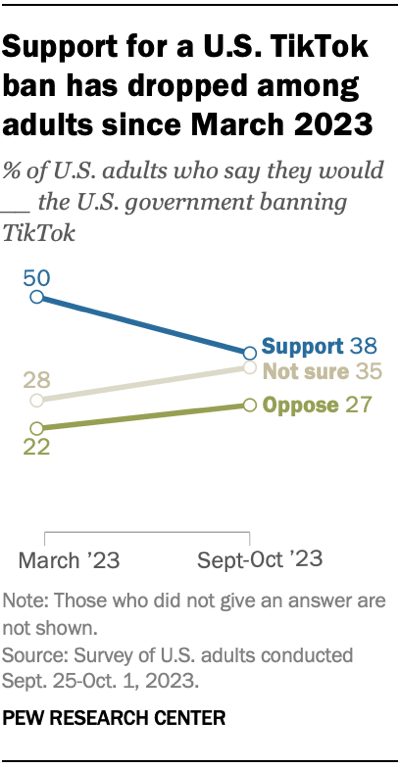

**Question**

How many American adults support the government banning TikTok during September?

Query key          : ec_2
Gold (correct)     : 38
Unevolved (seed)   : Based on the provided chart, we can determine the number of American adults who support the government banning TikTok in September.

The chart is titled "Support for a U.S. TikTok ban has dropped among adults since March 2023" and displays data from a survey conducted in September and October 2023.

- The blue line represents the percentage of adults who **support** the ban.
- The data point for September/October 2023 is labeled "Sept-Oct '23".
- The value on the blue line for this period is **38**.

Therefore, 38%   ← WRONG
Evolved            : 38   ← CORRECT
Reloaded `evolved` for the benchmark cell below.


In [ ]:
import os
from pathlib import Path
import gc
import sys
import torch
from IPython.display import display, Markdown, Image as IPyImage
from evaluate_evochartqa import find_contrastive_evochartqa_sample

MAX_CONTRASTIVE_SCAN = int(os.environ.get("MAX_CONTRASTIVE_SCAN", "120"))


def _vram_detach(mod_name: str) -> None:
    if mod_name in sys.modules:
        m = sys.modules.pop(mod_name)
        for attr in ("_model", "_processor"):
            if hasattr(m, attr):
                setattr(m, attr, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


_vram_detach("evolved_evochartqa_colab")
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(f"Scanning up to {MAX_CONTRASTIVE_SCAN} seed failures on EvoChart-QA …")
seed_v = load_module("_contrast_seed", PROJECT_ROOT / "seed_instruct.py")
evo_v = load_module("_contrast_evo", PROJECT_ROOT / "evolved_evochartqa.py")
pair = find_contrastive_evochartqa_sample(seed_v, evo_v, max_failure_checks=MAX_CONTRASTIVE_SCAN)
_vram_detach("_contrast_seed")
_vram_detach("_contrast_evo")

if pair is None:
    display(Markdown("### No contrastive example found"))
    print(
        f"No chart in the first {MAX_CONTRASTIVE_SCAN} seed failures where "
        "unevolved is wrong AND evolved is correct."
    )
    print("Try increasing MAX_CONTRASTIVE_SCAN or re-running evolution.")
else:
    CONTRASTIVE_SAMPLE = pair
    p = Path(pair["image_path"])
    if not p.is_file():
        raise FileNotFoundError(p)
    display(Markdown("## Contrastive chart from EvoChart-QA"))
    display(Markdown("*Unevolved (seed) is wrong; evolved matches gold.*"))
    display(IPyImage(filename=str(p)))
    q = pair["question"]
    display(Markdown("**Question**"))
    display(Markdown((q[:2000] + "…") if len(q) > 2000 else q))
    print("Query key          :", pair["key"])
    print("Gold (correct)     :", pair["gold"])
    print("Unevolved (seed)   :", pair["seed_response"], "  ← WRONG")
    print("Evolved            :", pair["evolved_response"], "  ← CORRECT")

evolved = load_module("evolved_evochartqa_colab", PROJECT_ROOT / "evolved_evochartqa.py")
print("Reloaded `evolved` for the benchmark cell below.")



In [ ]:
from evaluate_evochartqa import evaluate

print("=== BENCHMARK — after AlphaEvolve ===")
bench_after = evaluate(evolved, return_details=False)
for k in ("desc_accuracy", "num_desc_evaluated", "num_errors", "total_time", "avg_time_per_query"):
    print(f"  {k}: {bench_after[k]}")
print("\n=== SUMMARY (EvoChart-QA: seed → evolved) ===")
print(f"Accuracy: {bench_before['desc_accuracy']:.4f} → {bench_after['desc_accuracy']:.4f}")
print("\n=== SAME-SAMPLE BEFORE / AFTER ===")
try:
    q = SAMPLE["question"]
    print("Question (trim):", (q[:240] + "…") if len(q) > 240 else q)
    print("Gold     :", SAMPLE["gold"])
    print("Seed pred:", before_pred)
    print("Evolved  :", after_pred)
except NameError:
    print("(Re-run the two EXAMPLE cells so `before_pred` and `after_pred` exist.)")


=== BENCHMARK — after AlphaEvolve ===


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

  desc_accuracy: 0.4739583333333333
  num_desc_evaluated: 192
  num_errors: 0
  total_time: 82.38587164878845
  avg_time_per_query: 0.4290930815041065

=== SUMMARY (EvoChart-QA: seed → evolved) ===
Accuracy: 0.0104 → 0.4740

=== SAME-SAMPLE BEFORE / AFTER ===
Question (trim): What is the value of December?
Gold     : 32
Seed pred: Based on the provided chart, we can determine the value for December by following these steps:

1.  **Identify the time period:** The x-axis (horizontal axis) represents the timeline from October 2019 to June 2020.
2.  **Locate the month:** Find the label "DEC" on the x-axis. This corresponds to December.
3.  **Read the corresponding value:** The y-axis (vertical axis) represents the sales in thousands of USD. The black line, which represents the actual sales, shows the value for December.

The chart indicates that the actual sales in December 
Evolved  : 30
